[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/13_mlops.ipynb)

*Machine Learning from Scratch · Notebook 13 of 13*

# MLOps: Deploying & Monitoring Models

Take a model from notebook to production: experiment tracking and a model registry, data validation gates, saving and serving models, request validation, batch scoring, canary and shadow releases, latency budgets, point-in-time features, drift detection (PSI, KS), monitoring and retraining triggers.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Shipping a model is like opening a restaurant: the recipe (model) is only the start; you need a kitchen that runs every day, health checks, and a way to change the menu safely.

**What interviewers really test here:** Batch vs real-time serving, training-serving skew, model registry and rollback, canary and shadow releases, drift detection, and when to retrain.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why most models never reach production *(Basics)*
- [ ] 2. Reproducibility: tracking, registry, versions *(Core)*
- [ ] 3. Gates before training and before deploying *(Core)*
- [ ] 4. Serving: batch, real-time, and the training–serving gap *(Core)*
- [ ] 5. Releasing safely and sizing the service *(Core)*
- [ ] 6. Monitoring: drift, decay and retraining *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### The ML lifecycle

| Stage | Key question | Typical tools |
| --- | --- | --- |
| Data | is it complete, valid, versioned? | SQL, DVC, Great Expectations |
| Features | same logic offline and online? point-in-time correct? | feature stores (Feast) |
| Training | reproducible and tracked? | MLflow, W&B |
| Evaluation | better than production, on every key segment? | test sets, CI checks |
| Packaging | runs the same everywhere? | joblib, Docker |
| Serving | batch or real-time? fast enough? | FastAPI, KServe, SageMaker, Vertex AI |
| Release | safe rollout and rollback? | shadow, canary, blue/green |
| Monitoring | drifting? decaying? healthy? | Evidently, Prometheus + Grafana |

### Kinds of drift

- **Data (covariate) drift**: P(X) changes — new customer mix, a new app version sending different values.
- **Label (prior) drift**: P(y) changes — fraud rate doubles during a festival sale.
- **Concept drift**: P(y | X) changes — the same behaviour now means something different.
- **Upstream breakage**: a column renamed, units changed (rupees → paise), a join started dropping rows. Not "drift" but the most common cause of alerts.

### Drift statistics

| Statistic | For | Rule of thumb |
| --- | --- | --- |
| PSI = Σ (a − e) ln(a / e) | binned numeric or categorical | &lt; 0.1 stable · 0.1–0.25 moderate · &gt; 0.25 major |
| KS statistic | numeric | max ECDF gap; p-value from `ks_2samp` |
| χ² test | categorical | counts vs training shares |
| Jensen–Shannon distance | any distribution | bounded 0–1, symmetric |



With very large samples, tests flag tiny harmless shifts; judge by effect size (PSI) and by impact on model quality.

---
# Part 2: Lessons, step by step

## Lesson 1: Why most models never reach production

*Level: Basics*

A model in a notebook is a prototype. A model in production has to be **reproducible** (rebuild exactly the same one), **deployable** (answer requests in milliseconds or score millions of rows overnight), **monitored** (notice when it gets worse) and **maintainable** (retrain and roll back safely). **MLOps** is the set of practices that does this — DevOps plus data and models.



```python
data → validate → features → train → evaluate → register → deploy → monitor
  ↑                                                                    │
  └──────────────── retrain when drift or decay is detected ───────────┘
```



Tools you'll meet: **MLflow** or Weights & Biases (tracking, registry), **DVC** (data versions), **Great Expectations** (data checks), **FastAPI** (serving), **Docker** and **Kubernetes** (packaging, scaling), **Airflow** (scheduling), **Evidently** and **Grafana** (monitoring), and managed platforms such as SageMaker and Vertex AI. They run on servers, so here every idea is practised in plain Python you can run in the browser.

**✏️ Your turn:** you now have what you need for [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 2: Reproducibility: tracking, registry, versions

*Level: Core*

- **Experiment tracking**: log every run's parameters, metrics, code version (git commit), data version and the model file. Then "which settings gave 0.903?" has an answer.

```python
with mlflow.start_run():
    mlflow.log_params({"depth": 3}); mlflow.log_metric("val_auc", 0.903)
    mlflow.sklearn.log_model(pipeline, "model")
```


- **Data versioning**: store a fingerprint (hash) or a DVC version of the exact training data.
- **Model registry**: numbered versions with stages (Staging → Production → Archived). Promotion is a deliberate, recorded step, and rollback means pointing Production at the previous version.
- **Semantic versions** tell consumers what changed: a new input schema breaks callers (major), a retrain doesn't (minor).

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q11](#q11), [Q2](#q2), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 3: Gates before training and before deploying

*Level: Core*

Bad data silently makes bad models. Put a **data quality gate** before training: required columns present, null rates under limits, values in valid ranges, row counts plausible. If it fails, stop the pipeline and alert — don't train.



Before deploying, run **model CI** like software tests:




- Metric thresholds on a fixed test set (and per important segment).
- **Invariance tests**: changing something irrelevant (a name) must not change the prediction.
- **Directional tests**: raising income shouldn't lower a credit score.
- Latency and memory budgets.

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 4: Serving: batch, real-time, and the training–serving gap

*Level: Core*

**Batch** scoring runs on a schedule over many rows (nightly churn scores) — simple and cheap; process in chunks to fit in memory. **Real-time** serving answers one request at a time behind an API:



```python
from fastapi import FastAPI
from pydantic import BaseModel
import joblib

app = FastAPI()
model = joblib.load("model.joblib")          # the whole pipeline: preprocessing + model

class Applicant(BaseModel):
    age: int
    income: float

@app.post("/predict")
def predict(a: Applicant):
    return {"score": float(model.predict_proba([[a.age, a.income]])[0, 1])}
```



Pydantic validates every request (types, ranges) before it reaches the model. A **Dockerfile** installs pinned libraries and copies the code and model, so the same image runs on a laptop and in the cloud.



The classic production bug is **training–serving skew**: features computed one way in the training pipeline and another way in the serving code. Fixes: save preprocessing *inside* the model pipeline (a fitted scaler, never re-fitted on live data), share feature code, and build training sets with **point-in-time joins** so each label only sees feature values that existed at that moment.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q5](#q5), [Q15](#q15), [Q3](#q3), [Q20](#q20), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 5: Releasing safely and sizing the service

*Level: Core*

- **Shadow mode**: the new model scores live traffic but its answers are only logged. Compare with the current model at zero risk.
- **Canary**: send a small, sticky share of users (hash of the user id) to the new model, watch metrics, then widen. **Blue/green** keeps the old version running for instant rollback.
- **A/B test** the business metric before a full launch.



Size the service from the **tail**, not the average: p95 and p99 latency are what users feel. Little's law (requests in flight = arrival rate × time per request) gives the number of replicas, with headroom so they don't run at 100%.

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q19](#q19), [Q6](#q6), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 6: Monitoring: drift, decay and retraining

*Level: Advanced*

The world changes, so models decay. Watch three layers:




1. **Service health**: errors, latency, throughput.
2. **Data drift**: are inputs still like the training data? **PSI** on binned features (&lt; 0.1 stable, 0.1–0.25 watch, &gt; 0.25 act) and the **KS test** for numeric columns; also the prediction distribution itself.
3. **Model quality**: accuracy once true labels arrive — often days or weeks later — tracked on a rolling window.



**Concept drift** (the relationship between inputs and outcome changes, e.g. fraudsters adapt) can happen with no input drift at all, which is why labelled feedback matters. Retrain on a schedule, on alerts, or both — and every retrained model goes through the same gates and release steps as the first.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

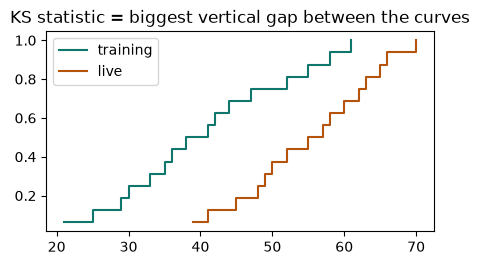

In [2]:
def drift_picture():
    train = [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42]
    live = [45, 49, 52, 55, 58, 60, 62, 65, 41, 50, 57, 63, 66, 70, 39, 48]
    fig, ax = plt.subplots(figsize=(5, 2.6))
    for data, label, color in [(train, "training", "#0f766e"), (live, "live", "#b45309")]:
        xs = np.sort(data)
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=label, color=color)
    ax.legend()
    ax.set_title("KS statistic = biggest vertical gap between the curves")


drift_picture()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q16](#q16), [Q8](#q8). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
from sklearn.linear_model import LogisticRegression

import math


<a id="q1"></a>
### Q1. Pick the Best Run

🟢 Warm-up · *Experiment tracking*

From tracked runs, return the run id with the highest validation AUC; break ties by the smaller train−validation gap (less overfitting).

**Examples**

- `runs = [{'run': 'r1', 'model': 'logreg', 'C': 1.0, 'val_auc': 0.861, 'train_auc': 0.872}, {'run': 'r2', 'model': 'gbm', 'depth': 3, 'val_auc': 0.903, 'train_auc': 0.931}, {'run': 'r3', 'model': 'gbm', 'depth': 8, 'val_auc': 0.897, 'train_auc': 0.998}, {'run': 'r4', 'model': 'rf', 'trees': 300, 'val_auc': 0.903, 'train_auc': 0.95}]` → `'r2'`
- `runs = [{'run': 'r1', 'model': 'logreg', 'C': 1.0, 'val_auc': 0.861, 'train_auc': 0.872}]` → `'r1'`

In [ ]:
def best_run(runs):
    """
    From tracked runs, return the run id with the highest validation AUC; break
    ties by the smaller train−validation gap (less overfitting).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_run, [
    (([{'run': 'r1', 'model': 'logreg', 'C': 1.0, 'val_auc': 0.861, 'train_auc': 0.872}, {'run': 'r2', 'model': 'gbm', 'depth': 3, 'val_auc': 0.903, 'train_auc': 0.931}, {'run': 'r3', 'model': 'gbm', 'depth': 8, 'val_auc': 0.897, 'train_auc': 0.998}, {'run': 'r4', 'model': 'rf', 'trees': 300, 'val_auc': 0.903, 'train_auc': 0.95}],), 'r2'),
    (([{'run': 'r1', 'model': 'logreg', 'C': 1.0, 'val_auc': 0.861, 'train_auc': 0.872}],), 'r1'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop that keeps the best so far.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A DataFrame sorted by two keys — what `mlflow.search_runs(order_by=...)` gives you.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** A loop that keeps the best so far.

```python
def best_run(runs):
    best = None
    for r in runs:
        gap = r["train_auc"] - r["val_auc"]
        if best is None or r["val_auc"] > best[1] or (r["val_auc"] == best[1] and gap < best[2]):
            best = (r["run"], r["val_auc"], gap)
    return best[0]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A DataFrame sorted by two keys — what `mlflow.search_runs(order_by=...)` gives you.

```python
def best_run(runs):
    df = pd.DataFrame(runs)
    df["gap"] = df["train_auc"] - df["val_auc"]
    return df.sort_values(["val_auc", "gap"], ascending=[False, True]).iloc[0]["run"]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop that keeps the best so far. That costs O(n) time and O(1) space."

"I can do better: A DataFrame sorted by two keys — what `mlflow.search_runs(order_by=...)` gives you. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/pick-the-best-run)

<a id="q2"></a>
### Q2. Same Data, Different Order?

🟢 Warm-up · *Dataset fingerprints*

Return True if two datasets (lists of row tuples) contain exactly the same rows, ignoring order — so a retrain can prove it used the same data.

**Examples**

- `a = [(1, 'a'), (2, 'b'), (2, 'b')], b = [(2, 'b'), (1, 'a'), (2, 'b')]` → `True`
- `a = [(1, 'a'), (2, 'b')], b = [(1, 'a'), (2, 'c')]` → `False`

In [ ]:
import hashlib

import json

def same_data(a, b):
    """
    Return True if two datasets (lists of row tuples) contain exactly the same
    rows, ignoring order — so a retrain can prove it used the same data.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(same_data, [
    (([(1, 'a'), (2, 'b'), (2, 'b')], [(2, 'b'), (1, 'a'), (2, 'b')]), True),
    (([(1, 'a'), (2, 'b')], [(1, 'a'), (2, 'c')]), False),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort both lists and compare.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Hash the sorted rows with SHA-256 — a short fingerprint you can store next to the model.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort both lists and compare.

```python
def same_data(a, b):
    return sorted(a) == sorted(b)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Hash the sorted rows with SHA-256 — a short fingerprint you can store next to the model.

```python
def same_data(a, b):
    fp = lambda rows: hashlib.sha256(json.dumps(sorted(rows)).encode()).hexdigest()
    return fp(a) == fp(b)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort both lists and compare. That costs O(n log n) time and O(n) space."

"I can do better: Hash the sorted rows with SHA-256 — a short fingerprint you can store next to the model. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/same-data-different-order)

<a id="q3"></a>
### Q3. Training–Serving Skew

🟢 Warm-up · *Same features online and offline?*

Compare features computed offline (training pipeline) and online (serving code) for the same request. Return the sorted names that differ by more than `tol`, or exist on one side only.

**Examples**

- `offline = {'age': 34, 'spend_7d': 120.0, 'ratio': 0.51}, online = {'age': 34, 'spend_7d': 118.0, 'ratio': 0.5100001, 'extra': 1}, tol = 0.001` → `['extra', 'spend_7d']`

In [ ]:
def skew(offline, online, tol):
    """
    Compare features computed offline (training pipeline) and online (serving
    code) for the same request. Return the sorted names that differ by more than
    tol, or exist on one side only.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skew, [
    (({'age': 34, 'spend_7d': 120.0, 'ratio': 0.51}, {'age': 34, 'spend_7d': 118.0, 'ratio': 0.5100001, 'extra': 1}, 0.001), ['extra', 'spend_7d']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the union of keys.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Align two Series and use `np.isclose`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over the union of keys.

```python
def skew(offline, online, tol):
    bad = []
    for k in set(offline) | set(online):
        if k not in offline or k not in online or abs(offline[k] - online[k]) > tol:
            bad.append(k)
    return sorted(bad)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Align two Series and use `np.isclose`.

```python
def skew(offline, online, tol):
    a, b = pd.Series(offline, dtype=float).align(pd.Series(online, dtype=float))
    ok = np.isclose(a, b, rtol=0, atol=tol)
    return sorted(a.index[~ok])
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the union of keys. That costs O(k) time and O(k) space."

"I can do better: Align two Series and use `np.isclose`. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/training-serving-skew)

<a id="q4"></a>
### Q4. Save and Reload a Model

🟢 Warm-up · *Serialisation*

Train `LogisticRegression()`, save it to bytes and load it back. Return the reloaded model's predictions for `X_new`.

**Examples**

- `X = [[0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4]], y = [0, 0, 0, 1, 1, 0, 1, 1], X_new = [[0.15, 0.5], [0.85, 0.5]]` → `[0, 1]`

In [ ]:
import io

import joblib

import pickle

def reload_predict(X, y, X_new):
    """
    Train LogisticRegression(), save it to bytes and load it back. Return the
    reloaded model's predictions for X_new.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reload_predict, [
    (([[0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4]], [0, 0, 0, 1, 1, 0, 1, 1], [[0.15, 0.5], [0.85, 0.5]]), [0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`pickle.dumps` / `pickle.loads`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`joblib.dump` / `joblib.load`, which handles big NumPy arrays efficiently — the usual choice for sklearn.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `pickle.dumps` / `pickle.loads`.

```python
def reload_predict(X, y, X_new):
    model = LogisticRegression().fit(X, y)
    blob = pickle.dumps(model)
    again = pickle.loads(blob)
    return again.predict(X_new).tolist()
```

**Cost:** O(model) time, O(model) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `joblib.dump` / `joblib.load`, which handles big NumPy arrays efficiently — the usual choice for sklearn.

```python
def reload_predict(X, y, X_new):
    buf = io.BytesIO()
    joblib.dump(LogisticRegression().fit(X, y), buf)
    buf.seek(0)
    return joblib.load(buf).predict(X_new).tolist()
```

**Cost:** O(model) time, O(model) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `pickle.dumps` / `pickle.loads`. That costs O(model) time and O(model) space."

"I can do better: `joblib.dump` / `joblib.load`, which handles big NumPy arrays efficiently — the usual choice for sklearn. That's O(model) time and O(model) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/save-and-reload-a-model)

<a id="q5"></a>
### Q5. Batch Scoring in Chunks

🟢 Warm-up · *Memory-safe inference*

Score `X_new` in chunks of `size` rows with a model trained on X, y. Return `(number of chunks, number predicted positive)`.

**Examples**

- `X = [[0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4]], y = [0, 0, 0, 1, 1, 0, 1, 1], X_new = [[0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4], [0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4], [0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4]], size = 5` → `(5, 12)`

In [ ]:
def chunked(X, y, X_new, size):
    """
    Score X_new in chunks of size rows with a model trained on X, y. Return
    (number of chunks, number predicted positive).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chunked, [
    (([[0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4]], [0, 0, 0, 1, 1, 0, 1, 1], [[0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4], [0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4], [0.1, 1.0], [0.4, 0.8], [0.35, 0.2], [0.8, 0.1], [0.9, 0.7], [0.2, 0.3], [0.7, 0.9], [0.6, 0.4]], 5), (5, 12)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slice with a range step and loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.array_split` into ⌈n/size⌉ parts and a generator.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Slice with a range step and loop.

```python
def chunked(X, y, X_new, size):
    model = LogisticRegression().fit(X, y)
    chunks = positives = 0
    for start in range(0, len(X_new), size):
        part = X_new[start:start + size]
        positives += int(sum(model.predict(part)))
        chunks += 1
    return (chunks, positives)
```

**Cost:** O(n) time, O(size) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.array_split` into ⌈n/size⌉ parts and a generator.

```python
def chunked(X, y, X_new, size):
    model = LogisticRegression().fit(X, y)
    parts = np.array_split(np.array(X_new), math.ceil(len(X_new) / size))
    return (len(parts), int(sum(model.predict(p).sum() for p in parts)))
```

**Cost:** O(n) time, O(size) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slice with a range step and loop. That costs O(n) time and O(size) space."

"I can do better: `np.array_split` into ⌈n/size⌉ parts and a generator. That's O(n) time and O(size) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/batch-scoring-in-chunks)

<a id="q6"></a>
### Q6. Latency Percentiles

🟢 Warm-up · *p50, p95, p99*

Return `(p50, p95, p99)` of request latencies in ms with linear interpolation, rounded to 2. Averages hide the slow tail; percentiles don't.

**Examples**

- `lat = [42, 38, 51, 47, 39, 44, 120, 41, 43, 40, 45, 300, 46, 37, 48, 50, 44, 42, 39, 41]` → `(43.5, 129.0, 265.8)`

In [ ]:
def latency(lat):
    """
    Return (p50, p95, p99) of request latencies in ms with linear interpolation,
    rounded to 2. Averages hide the slow tail; percentiles don't.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(latency, [
    (([42, 38, 51, 47, 39, 44, 120, 41, 43, 40, 45, 300, 46, 37, 48, 50, 44, 42, 39, 41],), (43.5, 129.0, 265.8)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort and interpolate at position (n − 1) × q.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.percentile(lat, [50, 95, 99])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort and interpolate at position (n − 1) × q.

```python
def latency(lat):
    s = sorted(lat)
    def q(p):
        pos = (len(s) - 1) * p
        lo = int(pos)
        return s[lo] + (s[min(lo + 1, len(s) - 1)] - s[lo]) * (pos - lo)
    return (round(q(0.5), 2), round(q(0.95), 2), round(q(0.99), 2))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.percentile(lat, [50, 95, 99])`.

```python
def latency(lat):
    return tuple(round(float(v), 2) for v in np.percentile(lat, [50, 95, 99]))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort and interpolate at position (n − 1) × q. That costs O(n log n) time and O(n) space."

"I can do better: `np.percentile(lat, [50, 95, 99])`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/latency-percentiles)

<a id="q7"></a>
### Q7. Shadow Mode Comparison

🟢 Warm-up · *Test on live traffic safely*

The new model runs in shadow (its answers are logged, not used). Return `(agreement %, indexes where they disagree)`, agreement rounded to 1.

**Examples**

- `live = [1, 0, 0, 1, 1, 0, 1, 0], shadow_preds = [1, 0, 1, 1, 0, 0, 1, 0]` → `(75.0, [2, 4])`

In [ ]:
def shadow(live, shadow_preds):
    """
    The new model runs in shadow (its answers are logged, not used). Return
    (agreement %, indexes where they disagree), agreement rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shadow, [
    (([1, 0, 0, 1, 1, 0, 1, 0], [1, 0, 1, 1, 0, 0, 1, 0]), (75.0, [2, 4])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with a counter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compare NumPy arrays; `np.flatnonzero` finds disagreements.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop with a counter.

```python
def shadow(live, shadow_preds):
    diff = []
    for i, (a, b) in enumerate(zip(live, shadow_preds)):
        if a != b:
            diff.append(i)
    return (round((len(live) - len(diff)) / len(live) * 100, 1), diff)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Compare NumPy arrays; `np.flatnonzero` finds disagreements.

```python
def shadow(live, shadow_preds):
    eq = np.array(live) == np.array(shadow_preds)
    return (round(float(eq.mean() * 100), 1), np.flatnonzero(~eq).tolist())
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with a counter. That costs O(n) time and O(n) space."

"I can do better: Compare NumPy arrays; `np.flatnonzero` finds disagreements. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/shadow-mode-comparison)

<a id="q8"></a>
### Q8. Should We Retrain?

🟢 Warm-up · *Retraining triggers*

Retrain if PSI &gt; 0.2 ('drift'), live accuracy fell more than 0.05 below the accuracy at deployment ('accuracy'), or the model is older than 30 days ('age'). Return the list of reasons in that order.

**Examples**

- `psi_value = 0.31, live_acc = 0.88, deploy_acc = 0.91, age_days = 12` → `['drift']`
- `psi_value = 0.05, live_acc = 0.8, deploy_acc = 0.9, age_days = 45` → `['accuracy', 'age']`
- `psi_value = 0.1, live_acc = 0.9, deploy_acc = 0.91, age_days = 3` → `[]`

In [ ]:
def retrain_reasons(psi_value, live_acc, deploy_acc, age_days):
    """
    Retrain if PSI > 0.2 ('drift'), live accuracy fell more than 0.05 below the
    accuracy at deployment ('accuracy'), or the model is older than 30 days
    ('age'). Return the list of reasons in that order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(retrain_reasons, [
    ((0.31, 0.88, 0.91, 12), ['drift']),
    ((0.05, 0.8, 0.9, 45), ['accuracy', 'age']),
    ((0.1, 0.9, 0.91, 3), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A list of (reason, condition) pairs filtered by a comprehension — easy to extend.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Three ifs.

```python
def retrain_reasons(psi_value, live_acc, deploy_acc, age_days):
    reasons = []
    if psi_value > 0.2:
        reasons.append("drift")
    if deploy_acc - live_acc > 0.05:
        reasons.append("accuracy")
    if age_days > 30:
        reasons.append("age")
    return reasons
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A list of (reason, condition) pairs filtered by a comprehension — easy to extend.

```python
def retrain_reasons(psi_value, live_acc, deploy_acc, age_days):
    rules = [("drift", psi_value > 0.2), ("accuracy", deploy_acc - live_acc > 0.05), ("age", age_days > 30)]
    return [name for name, hit in rules if hit]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three ifs. That costs O(1) time and O(1) space."

"I can do better: A list of (reason, condition) pairs filtered by a comprehension — easy to extend. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/should-we-retrain)

<a id="q9"></a>
### Q9. Bump the Model Version

🟢 Warm-up · *Semantic versioning*

Version 'MAJOR.MINOR.PATCH'. A new input schema bumps MAJOR, retraining on new data bumps MINOR, a bug fix bumps PATCH; lower parts reset to 0.

**Examples**

- `version = '2.3.7', change = 'schema'` → `'3.0.0'`
- `version = '2.3.7', change = 'retrain'` → `'2.4.0'`
- `version = '2.3.7', change = 'fix'` → `'2.3.8'`

In [ ]:
def bump(version, change):
    """
    Version 'MAJOR.MINOR.PATCH'. A new input schema bumps MAJOR, retraining on
    new data bumps MINOR, a bug fix bumps PATCH; lower parts reset to 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bump, [
    (('2.3.7', 'schema'), '3.0.0'),
    (('2.3.7', 'retrain'), '2.4.0'),
    (('2.3.7', 'fix'), '2.3.8'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split, then an if-chain.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Index of the part to bump from a dict; zero everything after it.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Split, then an if-chain.

```python
def bump(version, change):
    major, minor, patch = (int(p) for p in version.split("."))
    if change == "schema":
        major, minor, patch = major + 1, 0, 0
    elif change == "retrain":
        minor, patch = minor + 1, 0
    else:
        patch += 1
    return f"{major}.{minor}.{patch}"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Index of the part to bump from a dict; zero everything after it.

```python
def bump(version, change):
    parts = list(map(int, version.split(".")))
    i = {"schema": 0, "retrain": 1, "fix": 2}[change]
    parts = parts[:i] + [parts[i] + 1] + [0] * (2 - i)
    return ".".join(map(str, parts))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split, then an if-chain. That costs O(1) time and O(1) space."

"I can do better: Index of the part to bump from a dict; zero everything after it. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/bump-the-model-version)

<a id="q10"></a>
### Q10. Scale Serving Data With Training Statistics

🟢 Warm-up · *Fit once, reuse*

Standardise `serve` rows using the mean and (population) std learned from `train` — never statistics of the serving data. Round to 4.

**Examples**

- `train = [[1.0, 10.0], [2.0, 20.0], [3.0, 30.0]], serve = [[2.0, 40.0]]` → `[[0.0, 2.4495]]`

In [ ]:
from sklearn.preprocessing import StandardScaler

def scale_serving(train, serve):
    """
    Standardise serve rows using the mean and (population) std learned from
    train — never statistics of the serving data. Round to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scale_serving, [
    (([[1.0, 10.0], [2.0, 20.0], [3.0, 30.0]], [[2.0, 40.0]]), [[0.0, 2.4495]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each column's mean and std from train in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A fitted `StandardScaler` saved inside the model pipeline.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute each column's mean and std from train in loops.

```python
def scale_serving(train, serve):
    d = len(train[0])
    means = [sum(r[j] for r in train) / len(train) for j in range(d)]
    stds = [math.sqrt(sum((r[j] - means[j]) ** 2 for r in train) / len(train)) for j in range(d)]
    return [[round((r[j] - means[j]) / stds[j], 4) for j in range(d)] for r in serve]
```

**Cost:** O(nd) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A fitted `StandardScaler` saved inside the model pipeline.

```python
def scale_serving(train, serve):
    return np.round(StandardScaler().fit(train).transform(serve), 4).tolist()
```

**Cost:** O(nd) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each column's mean and std from train in loops. That costs O(nd) time and O(d) space."

"I can do better: A fitted `StandardScaler` saved inside the model pipeline. That's O(nd) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/scale-serving-data-with-training-statistics)

<a id="q11"></a>
### Q11. Promote a Model Version

🟡 Interview standard · *Model registry*

`versions` maps version → (stage, metric). Promote `candidate` to 'Production' only if its metric beats the current Production one by at least `margin`; the old one moves to 'Archived'. Return the updated stages, sorted by version.

**Examples**

- `versions = {1: ('Archived', 0.8), 2: ('Production', 0.85), 3: ('Staging', 0.87)}, candidate = 3, margin = 0.01` → `{1: 'Archived', 2: 'Archived', 3: 'Production'}`
- `versions = {1: ('Production', 0.85), 2: ('Staging', 0.855)}, candidate = 2, margin = 0.01` → `{1: 'Production', 2: 'Staging'}`

In [ ]:
def promote(versions, candidate, margin):
    """
    versions maps version → (stage, metric). Promote candidate to 'Production'
    only if its metric beats the current Production one by at least margin; the
    old one moves to 'Archived'. Return the updated stages, sorted by version.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(promote, [
    (({1: ('Archived', 0.8), 2: ('Production', 0.85), 3: ('Staging', 0.87)}, 3, 0.01), {1: 'Archived', 2: 'Archived', 3: 'Production'}),
    (({1: ('Production', 0.85), 2: ('Staging', 0.855)}, 2, 0.01), {1: 'Production', 2: 'Staging'}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the production version with a loop, compare, then rebuild the dict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dict comprehension that rewrites stages in one pass.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Find the production version with a loop, compare, then rebuild the dict.

```python
def promote(versions, candidate, margin):
    prod = None
    for v, (stage, metric) in versions.items():
        if stage == "Production":
            prod = v
    stages = {v: s for v, (s, m) in versions.items()}
    if prod is None or versions[candidate][1] >= versions[prod][1] + margin:
        if prod is not None:
            stages[prod] = "Archived"
        stages[candidate] = "Production"
    return dict(sorted(stages.items()))
```

**Cost:** O(v) time, O(v) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A dict comprehension that rewrites stages in one pass.

```python
def promote(versions, candidate, margin):
    prod = next((v for v, (s, _) in versions.items() if s == "Production"), None)
    ok = prod is None or versions[candidate][1] >= versions[prod][1] + margin
    new = {prod: "Archived", candidate: "Production"} if ok else {}
    return {v: new.get(v, s) for v, (s, _) in sorted(versions.items())}
```

**Cost:** O(v) time, O(v) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the production version with a loop, compare, then rebuild the dict. That costs O(v) time and O(v) space."

"I can do better: A dict comprehension that rewrites stages in one pass. That's O(v) time and O(v) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/promote-a-model-version)

<a id="q12"></a>
### Q12. Data Quality Gate

🟡 Interview standard · *Validate before you train*

Check a batch against `rules`: required columns, max share of nulls, and min/max value per column. Return a sorted list of failure messages: `'missing column: c'`, `'too many nulls: c'`, `'out of range: c'`.

**Examples**

- `batch = {'age': [25, None, 41, 230], 'income': [5.0, 7.5, None, None]}, rules = {'age': (0, 120, 0.3), 'income': (0, 1000, 0.25), 'city': (None, None, 0)}` → `['missing column: city', 'out of range: age', 'too many nulls: income']`

In [ ]:
def quality_gate(batch, rules):
    """
    Check a batch against rules: required columns, max share of nulls, and
    min/max value per column. Return a sorted list of failure messages: 'missing
    column: c', 'too many nulls: c', 'out of range: c'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quality_gate, [
    (({'age': [25, None, 41, 230], 'income': [5.0, 7.5, None, None]}, {'age': (0, 120, 0.3), 'income': (0, 1000, 0.25), 'city': (None, None, 0)}), ['missing column: city', 'out of range: age', 'too many nulls: income']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over rules and values.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A DataFrame: `isna().mean()` and `between`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over rules and values.

```python
def quality_gate(batch, rules):
    fails = []
    for col, (lo, hi, max_null) in rules.items():
        if col not in batch:
            fails.append("missing column: " + col)
            continue
        vals = batch[col]
        nulls = sum(v is None for v in vals)
        if nulls / len(vals) > max_null:
            fails.append("too many nulls: " + col)
        if any(v is not None and not (lo <= v <= hi) for v in vals):
            fails.append("out of range: " + col)
    return sorted(fails)
```

**Cost:** O(rows · cols) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A DataFrame: `isna().mean()` and `between`.

```python
def quality_gate(batch, rules):
    df = pd.DataFrame(batch)
    fails = [f"missing column: {c}" for c in rules if c not in df]
    for c, (lo, hi, max_null) in rules.items():
        if c in df:
            s = df[c]
            fails += [f"too many nulls: {c}"] * bool(s.isna().mean() > max_null)
            fails += [f"out of range: {c}"] * bool((~s.dropna().between(lo, hi)).any())
    return sorted(fails)
```

**Cost:** O(rows · cols) time, O(rows) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over rules and values. That costs O(rows · cols) time and O(1) space."

"I can do better: A DataFrame: `isna().mean()` and `between`. That's O(rows · cols) time and O(rows) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/data-quality-gate)

<a id="q13"></a>
### Q13. Population Stability Index

🟡 Interview standard · *Has the input shifted?*

Bin both samples using edges `bins` and return PSI = Σ (live% − train%) × ln(live% / train%), using 0.0001 in place of empty shares. Round to 4. Rule of thumb: &lt; 0.1 stable, &gt; 0.25 big shift.

**Examples**

- `train = [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], live = [45, 49, 52, 55, 58, 60, 62, 65, 41, 50, 57, 63, 66, 70, 39, 48], bins = [0, 30, 40, 50, 60, 100]` → `2.4385`
- `train = [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], live = [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], bins = [0, 30, 40, 50, 60, 100]` → `0.0`

In [ ]:
def psi(train, live, bins):
    """
    Bin both samples using edges bins and return PSI = Σ (live% − train%) ×
    ln(live% / train%), using 0.0001 in place of empty shares. Round to 4. Rule
    of thumb: < 0.1 stable, > 0.25 big shift.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(psi, [
    (([21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], [45, 49, 52, 55, 58, 60, 62, 65, 41, 50, 57, 63, 66, 70, 39, 48], [0, 30, 40, 50, 60, 100]), 2.4385),
    (([21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], [0, 30, 40, 50, 60, 100]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each sample into bins by hand, then sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.histogram` for both, then a vectorised sum.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count each sample into bins by hand, then sum.

```python
def psi(train, live, bins):
    def shares(xs):
        counts = [0] * (len(bins) - 1)
        for x in xs:
            for i in range(len(bins) - 1):
                last = i == len(bins) - 2
                if bins[i] <= x < bins[i + 1] or (last and x == bins[-1]):
                    counts[i] += 1
                    break
        return [max(c / len(xs), 0.0001) for c in counts]
    t, l = shares(train), shares(live)
    return round(sum((b - a) * math.log(b / a) for a, b in zip(t, l)), 4)
```

**Cost:** O(nb) time, O(b) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.histogram` for both, then a vectorised sum.

```python
def psi(train, live, bins):
    t = np.maximum(np.histogram(train, bins)[0] / len(train), 0.0001)
    l = np.maximum(np.histogram(live, bins)[0] / len(live), 0.0001)
    return round(float(((l - t) * np.log(l / t)).sum()), 4)
```

**Cost:** O(n log b) time, O(b) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each sample into bins by hand, then sum. That costs O(nb) time and O(b) space."

"I can do better: `np.histogram` for both, then a vectorised sum. That's O(n log b) time and O(b) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/population-stability-index)

<a id="q14"></a>
### Q14. Kolmogorov–Smirnov Drift Statistic

🟡 Interview standard · *Compare two distributions*

Return the KS statistic: the largest gap between the two samples' cumulative distribution curves, rounded to 4.

**Examples**

- `a = [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], b = [45, 49, 52, 55, 58, 60, 62, 65, 41, 50, 57, 63, 66, 70, 39, 48]` → `0.5625`
- `a = [21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], b = [42, 36, 30, 61, 58, 55, 52, 47, 44, 41, 38, 35, 33, 29, 25, 21]` → `0.0`

In [ ]:
from scipy import stats

def ks_stat(a, b):
    """
    Return the KS statistic: the largest gap between the two samples' cumulative
    distribution curves, rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ks_stat, [
    (([21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], [45, 49, 52, 55, 58, 60, 62, 65, 41, 50, 57, 63, 66, 70, 39, 48]), 0.5625),
    (([21, 25, 29, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 30, 36, 42], [42, 36, 30, 61, 58, 55, 52, 47, 44, 41, 38, 35, 33, 29, 25, 21]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Evaluate both ECDFs at every observed value and take the biggest difference.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`stats.ks_2samp(a, b).statistic` (its p-value says whether the gap is significant).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Evaluate both ECDFs at every observed value and take the biggest difference.

```python
def ks_stat(a, b):
    best = 0
    for x in sorted(set(a) | set(b)):
        fa = sum(v <= x for v in a) / len(a)
        fb = sum(v <= x for v in b) / len(b)
        best = max(best, abs(fa - fb))
    return round(best, 4)
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `stats.ks_2samp(a, b).statistic` (its p-value says whether the gap is significant).

```python
def ks_stat(a, b):
    return round(float(stats.ks_2samp(a, b).statistic), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Evaluate both ECDFs at every observed value and take the biggest difference. That costs O(n²) time and O(n) space."

"I can do better: `stats.ks_2samp(a, b).statistic` (its p-value says whether the gap is significant). That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/kolmogorov-smirnov-drift-statistic)

<a id="q15"></a>
### Q15. Validate an Inference Request

🟡 Interview standard · *API input checks*

Validate a JSON request against `SCHEMA` (type, min, max). Ints are accepted where floats are expected. Return `(ok, sorted errors)` with errors like `'age: missing'`, `'age: wrong type'`, `'age: out of range'`.

**Examples**

- `req = {'age': 17, 'income': 50000, 'city': 'Pune'}` → `(False, ['age: out of range'])`
- `req = {'age': '34', 'city': 'Pune'}` → `(False, ['age: wrong type', 'income: missing'])`
- `req = {'age': 30, 'income': 1.5, 'city': 'Goa'}` → `(True, [])`

In [ ]:
SCHEMA = {"age": (int, 18, 100), "income": (float, 0.0, 1e7), "city": (str, None, None)}

def validate_request(req):
    """
    Validate a JSON request against SCHEMA (type, min, max). Ints are accepted
    where floats are expected. Return (ok, sorted errors) with errors like 'age:
    missing', 'age: wrong type', 'age: out of range'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(validate_request, [
    (({'age': 17, 'income': 50000, 'city': 'Pune'},), (False, ['age: out of range'])),
    (({'age': '34', 'city': 'Pune'},), (False, ['age: wrong type', 'income: missing'])),
    (({'age': 30, 'income': 1.5, 'city': 'Goa'},), (True, [])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An if-chain per field.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A table-driven loop, like what pydantic generates from a model class.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** An if-chain per field.

```python
def validate_request(req):
    errors = []
    for field in SCHEMA:
        kind, lo, hi = SCHEMA[field]
        if field not in req:
            errors.append(field + ": missing")
            continue
        v = req[field]
        good_type = (isinstance(v, kind) or (kind is float and isinstance(v, int))) and not isinstance(v, bool)
        if not good_type:
            errors.append(field + ": wrong type")
        elif lo is not None and not (lo <= v <= hi):
            errors.append(field + ": out of range")
    return (len(errors) == 0, sorted(errors))
```

**Cost:** O(f) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A table-driven loop, like what pydantic generates from a model class.

```python
def validate_request(req):
    def check(field, kind, lo, hi):
        if field not in req:
            return "missing"
        v = req[field]
        if not isinstance(v, (kind, int) if kind is float else kind) or isinstance(v, bool):
            return "wrong type"
        if lo is not None and not lo <= v <= hi:
            return "out of range"
    errors = sorted(f"{f}: {e}" for f, spec in SCHEMA.items() if (e := check(f, *spec)))
    return (not errors, errors)
```

**Cost:** O(f) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An if-chain per field. That costs O(f) time and O(f) space."

"I can do better: A table-driven loop, like what pydantic generates from a model class. That's O(f) time and O(f) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `req = {'age': 17, 'income': 50000, 'city': 'Pune'}`

1. check() returns 'out of range'
2. check() returns None
3. check() returns None
4. validate\_request() returns (False, ['age: out of range'])

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/validate-an-inference-request)

<a id="q16"></a>
### Q16. Rolling Accuracy Alerts

🟡 Interview standard · *Monitoring with delayed labels*

Labels arrive as 1 (prediction was right) or 0. Return the indexes where accuracy over the last `w` labels drops below `floor`.

**Examples**

- `correct = [1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1], w = 4, floor = 0.5` → `[9, 10]`

In [ ]:
def accuracy_alerts(correct, w, floor):
    """
    Labels arrive as 1 (prediction was right) or 0. Return the indexes where
    accuracy over the last w labels drops below floor.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(accuracy_alerts, [
    (([1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1], 4, 0.5), [9, 10]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recompute each window's mean in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`rolling(w).mean()`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Recompute each window's mean in a loop.

```python
def accuracy_alerts(correct, w, floor):
    alerts = []
    for i in range(w - 1, len(correct)):
        if sum(correct[i - w + 1:i + 1]) / w < floor:
            alerts.append(i)
    return alerts
```

**Cost:** O(nw) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `rolling(w).mean()`.

```python
def accuracy_alerts(correct, w, floor):
    r = pd.Series(correct).rolling(w).mean()
    return r.index[r < floor].tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recompute each window's mean in a loop. That costs O(nw) time and O(1) space."

"I can do better: `rolling(w).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/rolling-accuracy-alerts)

<a id="q17"></a>
### Q17. Pre-Deployment Checks

🟡 Interview standard · *CI for models*

Return the names of failed checks, in order: 'auc' (AUC below `min_auc`), 'latency' (p95 above `max_p95`), 'invariance' (changing an irrelevant field such as the user's name changed any prediction).

**Examples**

- `auc = 0.86, min_auc = 0.85, p95 = 80, max_p95 = 100, preds = [0.2, 0.7], preds_renamed = [0.2, 0.7]` → `[]`
- `auc = 0.82, min_auc = 0.85, p95 = 140, max_p95 = 100, preds = [0.2, 0.7], preds_renamed = [0.2, 0.71]` → `['auc', 'latency', 'invariance']`

In [ ]:
def predeploy(auc, min_auc, p95, max_p95, preds, preds_renamed):
    """
    Return the names of failed checks, in order: 'auc' (AUC below min_auc),
    'latency' (p95 above max_p95), 'invariance' (changing an irrelevant field
    such as the user's name changed any prediction).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(predeploy, [
    ((0.86, 0.85, 80, 100, [0.2, 0.7], [0.2, 0.7]), []),
    ((0.82, 0.85, 140, 100, [0.2, 0.7], [0.2, 0.71]), ['auc', 'latency', 'invariance']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three ifs appending names.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Checks as data, evaluated in a comprehension; `np.allclose` for invariance.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Three ifs appending names.

```python
def predeploy(auc, min_auc, p95, max_p95, preds, preds_renamed):
    failed = []
    if auc < min_auc:
        failed.append("auc")
    if p95 > max_p95:
        failed.append("latency")
    for a, b in zip(preds, preds_renamed):
        if abs(a - b) > 1e-9:
            failed.append("invariance")
            break
    return failed
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Checks as data, evaluated in a comprehension; `np.allclose` for invariance.

```python
def predeploy(auc, min_auc, p95, max_p95, preds, preds_renamed):
    checks = {"auc": auc >= min_auc, "latency": p95 <= max_p95,
              "invariance": np.allclose(preds, preds_renamed, rtol=0, atol=1e-9)}
    return [name for name, ok in checks.items() if not ok]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three ifs appending names. That costs O(n) time and O(1) space."

"I can do better: Checks as data, evaluated in a comprehension; `np.allclose` for invariance. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/pre-deployment-checks)

<a id="q18"></a>
### Q18. How Many Replicas?

🟡 Interview standard · *Capacity planning*

Peak traffic is `rps` requests/second, each takes `ms` milliseconds, each replica handles `workers` requests at once, and you target `util` utilisation. By Little's law, in-flight requests = rps × seconds. Return the replicas needed (round up).

**Examples**

- `rps = 400, ms = 50, workers = 4, util = 0.7` → `8`
- `rps = 1000, ms = 120, workers = 8, util = 0.6` → `25`

In [ ]:
def replicas(rps, ms, workers, util):
    """
    Peak traffic is rps requests/second, each takes ms milliseconds, each
    replica handles workers requests at once, and you target util utilisation.
    By Little's law, in-flight requests = rps × seconds. Return the replicas
    needed (round up).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(replicas, [
    ((400, 50, 4, 0.7), 8),
    ((1000, 120, 8, 0.6), 25),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute in-flight requests, then capacity per replica, step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One expression with `math.ceil`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute in-flight requests, then capacity per replica, step by step.

```python
def replicas(rps, ms, workers, util):
    in_flight = rps * ms / 1000
    usable_per_replica = workers * util
    n = 0
    while n * usable_per_replica < in_flight:
        n += 1
    return n
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** One expression with `math.ceil`.

```python
def replicas(rps, ms, workers, util):
    return math.ceil(round(rps * ms / 1000 / (workers * util), 9))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute in-flight requests, then capacity per replica, step by step. That costs O(1) time and O(1) space."

"I can do better: One expression with `math.ceil`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/how-many-replicas)

<a id="q19"></a>
### Q19. Canary Routing by Hash

🔴 Stretch · *Sticky gradual rollout*

Send a user to the new model if CRC-32(user id) % 100 &lt; `pct`, so each user always sees the same version. Return the users routed to the canary.

**Examples**

- `users = ['u1', 'u2', 'u3', 'u4', 'u5', 'u6', 'u7', 'u8'], pct = 30` → `['u1', 'u3']`
- `users = ['alice', 'bob'], pct = 0` → `[]`

In [ ]:
import zlib

def canary(users, pct):
    """
    Send a user to the new model if CRC-32(user id) % 100 < pct, so each user
    always sees the same version. Return the users routed to the canary.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(canary, [
    ((['u1', 'u2', 'u3', 'u4', 'u5', 'u6', 'u7', 'u8'], 30), ['u1', 'u3']),
    ((['alice', 'bob'], 0), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Implement CRC-32 bit by bit (polynomial 0xEDB88320).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`zlib.crc32`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Implement CRC-32 bit by bit (polynomial 0xEDB88320).

```python
def canary(users, pct):
    def crc32(data):
        crc = 0xFFFFFFFF
        for byte in data:
            crc ^= byte
            for _ in range(8):
                crc = (crc >> 1) ^ 0xEDB88320 if crc & 1 else crc >> 1
        return crc ^ 0xFFFFFFFF
    return [u for u in users if crc32(u.encode()) % 100 < pct]
```

**Cost:** O(chars · 8) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `zlib.crc32`.

```python
def canary(users, pct):
    return [u for u in users if zlib.crc32(u.encode()) % 100 < pct]
```

**Cost:** O(chars) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Implement CRC-32 bit by bit (polynomial 0xEDB88320). That costs O(chars · 8) time and O(1) space."

"I can do better: `zlib.crc32`. That's O(chars) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/canary-routing-by-hash)

<a id="q20"></a>
### Q20. Point-in-Time Feature Join

🔴 Stretch · *No peeking at the future*

For each label (user, time, y), attach the user's most recent feature value at or before that time (None if none). Return `(user, time, feature, y)` rows sorted by user then time.

**Examples**

- `labels = [('u1', 5, 1), ('u1', 12, 0), ('u2', 7, 1), ('u2', 2, 0)], feats = [('u1', 1, 10.0), ('u1', 6, 14.0), ('u1', 11, 20.0), ('u2', 3, 3.0), ('u2', 8, 9.0)]` → `[('u1', 5, 10.0, 1), ('u1', 12, 20.0, 0), ('u2', 2, None, 0), ('u2', 7, 3.0, 1)]`

In [ ]:
def point_in_time(labels, feats):
    """
    For each label (user, time, y), attach the user's most recent feature value
    at or before that time (None if none). Return (user, time, feature, y) rows
    sorted by user then time.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(point_in_time, [
    (([('u1', 5, 1), ('u1', 12, 0), ('u2', 7, 1), ('u2', 2, 0)], [('u1', 1, 10.0), ('u1', 6, 14.0), ('u1', 11, 20.0), ('u2', 3, 3.0), ('u2', 8, 9.0)]), [('u1', 5, 10.0, 1), ('u1', 12, 20.0, 0), ('u2', 2, None, 0), ('u2', 7, 3.0, 1)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each label, scan that user's feature rows for the latest time ≤ label time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`pd.merge_asof(by='user')` — exactly what feature stores do to build training sets.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each label, scan that user's feature rows for the latest time ≤ label time.

```python
def point_in_time(labels, feats):
    out = []
    for user, t, y in sorted(labels):
        best = None
        for fu, ft, value in feats:
            if fu == user and ft <= t and (best is None or ft > best[0]):
                best = (ft, value)
        out.append((user, t, best[1] if best else None, y))
    return out
```

**Cost:** O(n · m) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `pd.merge_asof(by='user')` — exactly what feature stores do to build training sets.

```python
def point_in_time(labels, feats):
    L = pd.DataFrame(labels, columns=["user", "t", "y"]).sort_values("t")
    F = pd.DataFrame(feats, columns=["user", "t", "feature"]).sort_values("t")
    m = pd.merge_asof(L, F, on="t", by="user").sort_values(["user", "t"])
    return [(u, t, None if pd.isna(f) else f, y) for u, t, y, f in m[["user", "t", "y", "feature"]].itertuples(index=False)]
```

**Cost:** O((n + m) log(n + m)) time, O(n + m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each label, scan that user's feature rows for the latest time ≤ label time. That costs O(n · m) time and O(1) space."

"I can do better: `pd.merge_asof(by='user')` — exactly what feature stores do to build training sets. That's O((n + m) log(n + m)) time and O(n + m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/mlops/point-in-time-feature-join)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Batch or real-time serving?</b></summary>

Batch when predictions can be computed ahead of time (daily churn scores, recommendations refreshed nightly): simpler and cheaper. Real-time when the answer depends on fresh input at request time (fraud checks, search ranking).

</details>

<details>
<summary><b>2. What is training–serving skew and how do you prevent it?</b></summary>

A difference between features or preprocessing at training time and at serving time. Prevent it by packaging preprocessing inside the model pipeline, sharing feature code or a feature store, and comparing logged online features with offline recomputation.

</details>

<details>
<summary><b>3. How do you know a deployed model is getting worse?</b></summary>

Monitor input and prediction drift continuously, and model quality once labels arrive, on rolling windows and per segment, with alerts on thresholds.

</details>

<details>
<summary><b>4. What does a model registry give you?</b></summary>

Versioned models with metadata (metrics, data and code versions), stage transitions with an audit trail, and one-step rollback to a previous version.

</details>

<details>
<summary><b>5. Shadow vs canary deployment?</b></summary>

Shadow runs the new model on live traffic without using its answers — zero user risk. Canary actually serves a small share of users with the new model, so it tests real-world effects but carries limited risk.

</details>

<details>
<summary><b>6. Why use Docker for ML?</b></summary>

It packages the code, exact library versions, system dependencies and model into one image, so it behaves identically on a laptop, in CI and in production, and scales easily on Kubernetes.

</details>

<details>
<summary><b>7. What is a point-in-time join?</b></summary>

Joining each training label only with feature values that existed at the label's timestamp, so the model never trains on information from the future.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why most models never reach production
- [ ] I can explain: Reproducibility: tracking, registry, versions
- [ ] I can explain: Gates before training and before deploying
- [ ] I can explain: Serving: batch, real-time, and the training–serving gap
- [ ] I can explain: Releasing safely and sizing the service
- [ ] I can explain: Monitoring: drift, decay and retraining

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Rolling Accuracy Alerts
- [ ] [Q17](#q17) Pre-Deployment Checks
- [ ] [Q18](#q18) How Many Replicas?
- [ ] [Q19](#q19) Canary Routing by Hash
- [ ] [Q20](#q20) Point-in-Time Feature Join

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.